# 🍎 Pipeline de Preparação de Dataset — Apple Disease CNN

| Bloco | Função |
|-------|--------|
| 1 | Consolidação + normalização de classes |
| 2A | Pré-dedup RAW (MD5 + pHash + CNN@0.85 + detecção de augmentações) |
| 2B | A_Cinema_test.py — só nas imagens únicas |
| 3 | Pós-dedup CLEAN (MD5 + pHash + CNN@0.78 + detecção de augmentações) |
| 4 | Auto-rotulagem + `Incerteza` |
| 5 | Human-on-the-loop |
| 6 | Visão geral |

### Detecção de augmentações
Para cada imagem **única confirmada**, guarda-se **7 embeddings**:
original + flip H + flip V + rot90 + rot180 + zoom in + zoom out.  
Qualquer nova imagem é comparada contra **todos** estes — apanha flips, rotações e stretches.

---
## ⚙️ BLOCO 0 — Configuração Global

In [1]:
import os, re

BASE_DIR = r"C:\Users\Utilizador\OneDrive\Área de Trabalho\script_apple"
PASTA_DATASETS = r"C:\Users\Utilizador\OneDrive\Área de Trabalho\dataALL"  # <- EDITA AQUI

# ── Mapeamento de keywords → classe canónica ─────────────────────────────────
# O matcher normaliza underscores/espaços/hífens antes de comparar,
# por isso 'black pox', 'black_pox' e 'Black-Pox' são todos igualmente detectados.
#
# ⚠️  'black_pox' e 'powdery_mildew' estavam a criar pastas separadas
#     porque não tinham mapeamento. Edita as classes de destino abaixo.
MAPA_CLASSES_KEYWORDS = {
    # ── Classes principais ─────────────────────────────────────────────────
    'Anthracnose'    : 'Anthracnose',
    'Blotch'         : 'Blotch',
    'Healthy'        : 'Healthy',
    'Scab'           : 'Scab',
    'Rot'            : 'Rot',      # Rot, Rotten, Rot_dupe, Rot_dupe_80_85...
    # ── Variantes encontradas nos datasets ────────────────────────────────
    'black_pox'      : 'Pox',      # <- EDITA se necessário (black pox é podridão)
    'black_rot'      : 'Rot',
    'powdery_mildew' : 'Mildew',     # <- EDITA se necessário (aspecto semelhante a Scab)
    'powdery'        : 'Mildew',     # apanha 'powdery mildew' com espaço
    'mildew'         : 'Mildew',
}

PIPELINE_DIR  = os.path.join(BASE_DIR, "pipeline_ALL_night")
DIR_RAW       = os.path.join(PIPELINE_DIR, "_1_raw_consolidated")
DIR_RAW_DEDUP = os.path.join(PIPELINE_DIR, "_2a_raw_prededup")
DIR_CLEAN     = os.path.join(PIPELINE_DIR, "_2b_clean_processed")
DIR_DEDUPED   = os.path.join(PIPELINE_DIR, "_3_deduped_final")
DIR_INCERTEZA = os.path.join(PIPELINE_DIR, "Incerteza")
DIR_FINAL     = os.path.join(PIPELINE_DIR, "_4_dataset_final")
MODEL_PATH    = os.path.join(BASE_DIR, "melhor_modelo_multiclass_smooth.pth")

CLASSES_MODELO = ['Anthracnose', 'Blotch', 'Healthy', 'Rot', 'Scab']
CONFIANCA_MIN  = 0.70
IMG_EXTS       = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# ── Limiares de deduplicação ──────────────────────────────────────────────────
# pHash Hamming distance máxima (0=idêntico, 64=completamente diferente)
PHASH_HAMMING_PRE   = 10   # pré-dedup (RAW, fundos variados → um pouco conservador)
PHASH_HAMMING_POST  = 12    # +Conservador (era 8)   # pós-dedup (limpo, fundo igual → pode ser mais agressivo)
PHASH_HAMMING_SEQUENCIAL  = 18

# CNN cosine similarity mínima para considerar duplicado
CNN_COSINE_PRE   = 0.85    # pré-dedup: apanha as cópias mais óbvias
CNN_COSINE_POST     = 0.90 # +Conservador (era 0.95)    # pós-dedup: mais agressivo (apanha mesma maçã, ângulo diferente)

# Detecção de augmentações
# True = guarda 7 embeddings por imagem única (original + flips + rotações + zoom)
# Apanha: flip horizontal/vertical, rotações 90°/180°, zoom in/out, stretch
DETECT_AUGMENTACOES = True

# ─────────────────────────────────────────────────────────────────────────────
def normalizar_nome(nome):
    """Normaliza separadores: 'black pox', 'black_pox', 'black-pox' → 'black_pox'."""
    return re.sub(r'[\s\-]+', '_', nome.lower())

def normalizar_classe(nome_pasta, mapa):
    nl = normalizar_nome(nome_pasta)
    for kw, cls in mapa.items():
        if normalizar_nome(kw) in nl:
            return cls, True
    return nome_pasta, False

print("✅ Configuração carregada!")
print(f"   Pasta datasets : {PASTA_DATASETS}")
print(f"   Modelo         : {MODEL_PATH}")
print(f"\n   [Pré-dedup]  pHash Hamming ≤ {PHASH_HAMMING_PRE} | CNN cosine ≥ {CNN_COSINE_PRE}")
print(f"   [Pós-dedup]  pHash Hamming ≤ {PHASH_HAMMING_POST} | CNN cosine ≥ {CNN_COSINE_POST}")
print(f"   Detecção de augmentações: {'✅ ACTIVA' if DETECT_AUGMENTACOES else '❌ desactivada'}")

ok = os.path.isdir(PASTA_DATASETS)
print(f"\n   Pasta encontrada: {'✅' if ok else '❌ NÃO ENCONTRADA!'}")
if ok:
    sps = sorted([d for d in os.listdir(PASTA_DATASETS) if os.path.isdir(os.path.join(PASTA_DATASETS, d))])
    print(f"   Subpastas ({len(sps)}):")
    for sp in sps:
        cls, match = normalizar_classe(sp, MAPA_CLASSES_KEYWORDS)
        tag = f"→ '{cls}'" + (" 🔀" if sp != cls else " ✅")
        if not match: tag = "⚠️  SEM KEYWORD — adiciona ao MAPA_CLASSES_KEYWORDS!"
        print(f"     '{sp}' {tag}")

✅ Configuração carregada!
   Pasta datasets : C:\Users\Utilizador\OneDrive\Área de Trabalho\dataALL
   Modelo         : C:\Users\Utilizador\OneDrive\Área de Trabalho\script_apple\melhor_modelo_multiclass_smooth.pth

   [Pré-dedup]  pHash Hamming ≤ 10 | CNN cosine ≥ 0.85
   [Pós-dedup]  pHash Hamming ≤ 12 | CNN cosine ≥ 0.9
   Detecção de augmentações: ✅ ACTIVA

   Pasta encontrada: ✅
   Subpastas (35):
     'Anthracnose' → 'Anthracnose' ✅
     'Anthracnose_dupe_80_85' → 'Anthracnose' 🔀
     'Anthracnose_dupe_85_plus' → 'Anthracnose' 🔀
     'Apple_Blotch' → 'Blotch' 🔀
     'Apple_Healthy' → 'Healthy' 🔀
     'Apple_Powdery_mildew' → 'Mildew' 🔀
     'Apple_brown_rot' → 'Rot' 🔀
     'Apple_cork_spots' ⚠️  SEM KEYWORD — adiciona ao MAPA_CLASSES_KEYWORDS!
     'Apple_rot' → 'Rot' 🔀
     'Apple_scab' → 'Scab' 🔀
     'Black Pox' → 'Pox' 🔀
     'Black Pox_dupe_80_85' → 'Pox' 🔀
     'Black Pox_dupe_85_plus' → 'Pox' 🔀
     'Black Rot' → 'Rot' 🔀
     'Black Rot_dupe_80_85' → 'Rot' 🔀
     'Black Ro

---
## 📦 BLOCO 1 — Consolidação em `_1_raw_consolidated`
Estrutura de **2 níveis** (`PASTA_DATASETS → subpasta_classe → imagens`).  
Normaliza nomes com separadores inconsistentes (`black pox`, `black_pox`, `Black-Pox` → mesmo destino).

In [2]:
import os, shutil
from collections import defaultdict

def consolidar(pasta_raiz, dir_destino, mapa, img_exts=IMG_EXTS):
    os.makedirs(dir_destino, exist_ok=True)
    contagem = defaultdict(int)
    mapa_pastas = defaultdict(list)
    sem_match = []; total = 0

    if not os.path.isdir(pasta_raiz):
        print(f"❌ {pasta_raiz} não encontrada"); return contagem

    sps = sorted([d for d in os.listdir(pasta_raiz) if os.path.isdir(os.path.join(pasta_raiz, d))])
    print(f"📦 {len(sps)} subpastas:\n")

    for sp in sps:
        caminho = os.path.join(pasta_raiz, sp)
        cls, match = normalizar_classe(sp, mapa)
        if not match:
            sem_match.append(sp)
            print(f"   ⚠️  '{sp}' → SEM KEYWORD (copiado tal-qual — VERIFICA!)")
        elif normalizar_nome(sp) != normalizar_nome(cls):
            print(f"   🔀 '{sp}' → '{cls}'")
        else:
            print(f"   ✅ '{sp}'")

        mapa_pastas[cls].append(sp)
        dst_cls = os.path.join(dir_destino, cls)
        os.makedirs(dst_cls, exist_ok=True)
        n = 0
        for root, _, files in os.walk(caminho):
            for f in files:
                _, ext = os.path.splitext(f)
                if ext.lower() not in img_exts: continue
                src = os.path.join(root, f)
                dst = os.path.join(dst_cls, f)
                if os.path.exists(dst):
                    nb, ex = os.path.splitext(f); c = 1
                    while os.path.exists(dst): dst = os.path.join(dst_cls, f"{nb}_dup{c}{ex}"); c += 1
                shutil.copy2(src, dst)   # CÓPIA — original intacto
                contagem[cls] += 1; total += 1; n += 1
        print(f"      → {n} imagens copiadas")

    print("\n" + "═" * 58)
    for cls in sorted(contagem):
        print(f"  {cls:<22} {contagem[cls]:>5} imgs ← {', '.join(mapa_pastas[cls])}")
    print(f"  Total: {total}")
    if sem_match:
        print(f"\n  ⚠️  CLASSES SEM KEYWORD (adiciona ao MAPA_CLASSES_KEYWORDS):")
        for s in sem_match: print(f"     '{s}'")
    return contagem

contagem_bloco1 = consolidar(PASTA_DATASETS, DIR_RAW, MAPA_CLASSES_KEYWORDS)
print("\n✅ BLOCO 1 concluído!")

📦 35 subpastas:

   ✅ 'Anthracnose'
      → 147 imagens copiadas
   🔀 'Anthracnose_dupe_80_85' → 'Anthracnose'
      → 177 imagens copiadas
   🔀 'Anthracnose_dupe_85_plus' → 'Anthracnose'
      → 19 imagens copiadas
   🔀 'Apple_Blotch' → 'Blotch'
      → 378 imagens copiadas
   🔀 'Apple_Healthy' → 'Healthy'
      → 3077 imagens copiadas
   🔀 'Apple_Powdery_mildew' → 'Mildew'
      → 59 imagens copiadas
   🔀 'Apple_brown_rot' → 'Rot'
      → 405 imagens copiadas
   ⚠️  'Apple_cork_spots' → SEM KEYWORD (copiado tal-qual — VERIFICA!)
      → 19 imagens copiadas
   🔀 'Apple_rot' → 'Rot'
      → 169 imagens copiadas
   🔀 'Apple_scab' → 'Scab'
      → 172 imagens copiadas
   🔀 'Black Pox' → 'Pox'
      → 59 imagens copiadas
   🔀 'Black Pox_dupe_80_85' → 'Pox'
      → 327 imagens copiadas
   🔀 'Black Pox_dupe_85_plus' → 'Pox'
      → 79 imagens copiadas
   🔀 'Black Rot' → 'Rot'
      → 183 imagens copiadas
   🔀 'Black Rot_dupe_80_85' → 'Rot'
      → 331 imagens copiadas
   🔀 'Black Rot_dupe_8

---
## ⚡ BLOCO 2A — Pré-Dedup RAW (MD5 + pHash + CNN + Augmentações)

Remove duplicados **antes** do Cinema para não desperdiçar tempo de `rembg`.

### Detecção de augmentações (novidade!)
Para cada imagem única confirmada, guarda-se **7 embeddings CNN**:

| # | Transformação | Apanha |
|---|---------------|--------|
| 1 | Original | Cópia directa |
| 2 | Flip horizontal | `ImageOps.mirror` |
| 3 | Flip vertical | `ImageOps.flip` |
| 4 | Rotação 90° | `img.rotate(90)` |
| 5 | Rotação 180° | `img.rotate(180)` |
| 6 | Zoom in (crop 85%) | Apanha augmentações de scale-up |
| 7 | Zoom out (pad 15%) | Apanha augmentações de scale-down / stretch |

Qualquer nova imagem cujo embedding bata em **qualquer um dos 7** → duplicado.

In [3]:
import os, shutil, hashlib
import imagehash
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict

DIR_PRE_DUPES = os.path.join(PIPELINE_DIR, "_2a_prededup_removidos")
os.makedirs(DIR_RAW_DEDUP, exist_ok=True)
os.makedirs(DIR_PRE_DUPES, exist_ok=True)

print("=" * 62)
print("  BLOCO 2A: Pré-Dedup RAW")
print(f"  Camada 1: MD5")
print(f"  Camada 2: pHash Hamming ≤ {PHASH_HAMMING_PRE}")
print(f"  Camada 3: CNN cosine ≥ {CNN_COSINE_PRE}  {'+ augmentações (7 transforms)' if DETECT_AUGMENTACOES else ''}")
print("=" * 62)

# ── Carregar CNN ──────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n🖥️  CNN device: {device.type.upper()}")

base_m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
feat = torch.nn.Sequential(*list(base_m.children())[:-1]).to(device)
feat.eval()   # pesos congelados — sem treino

preproc = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

def cnn_single(img_pil):
    t = preproc(img_pil.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():   # sem gradientes — pesos nunca actualizados
        return F.normalize(torch.flatten(feat(t), 1), dim=1)

def gerar_variantes(img_pil):
    """
    Gera 7 versões da imagem para detecção de augmentações:
    original, flip H, flip V, rot90, rot180, zoom-in, zoom-out
    """
    from PIL import ImageOps
    w, h = img_pil.size
    # Zoom in: crop central 85% → resize para tamanho original
    crop = 0.85
    cx, cy = int(w*(1-crop)/2), int(h*(1-crop)/2)
    zoom_in  = img_pil.crop((cx, cy, w-cx, h-cy)).resize((w, h), Image.LANCZOS)
    # Zoom out: adiciona padding 15% → resize para tamanho original
    pad = int(min(w,h) * 0.15)
    zoom_out = ImageOps.expand(img_pil, border=pad, fill=0).resize((w, h), Image.LANCZOS)
    return [
        img_pil,                                    # 1. original
        ImageOps.mirror(img_pil),                   # 2. flip horizontal
        ImageOps.flip(img_pil),                     # 3. flip vertical
        img_pil.rotate(90,  expand=True),           # 4. rotação 90°
        img_pil.rotate(180, expand=True),           # 5. rotação 180°
        zoom_in,                                    # 6. zoom in (scale-up aug)
        zoom_out,                                   # 7. zoom out / stretch aug
    ]

def obter_embeddings_para_banco(path, detectar_aug):
    """Para ADICIONAR ao banco: devolve 7 embeddings (ou 1 se aug desactivado)."""
    img = Image.open(path).convert('RGB')
    if detectar_aug:
        return [cnn_single(v) for v in gerar_variantes(img)]
    return [cnn_single(img)]

def obter_embedding_novo(path):
    """Para imagem NOVA: só o embedding original (comparado contra banco com augmentações)."""
    return cnn_single(Image.open(path).convert('RGB'))

def e_cnn_duplicado(emb_novo, banco_cnn, limiar):
    """Verifica se emb_novo é similar a QUALQUER embedding no banco (inclui augmentações)."""
    for embs_ref, path_ref in banco_cnn:
        for emb_ref in embs_ref:
            if F.cosine_similarity(emb_novo, emb_ref).item() >= limiar:
                return True, path_ref
    return False, None

def md5f(path):
    h = hashlib.md5()
    with open(path,'rb') as f: h.update(f.read())
    return h.hexdigest()

def mover_dup(img_path, cls, pasta_dup, camada, ref):
    pd = os.path.join(pasta_dup, cls)
    os.makedirs(pd, exist_ok=True)
    f = os.path.basename(img_path)
    dst = os.path.join(pd, f)
    if os.path.exists(dst):
        nb, ex = os.path.splitext(f); c = 1
        while os.path.exists(dst): dst = os.path.join(pd, f"{nb}_{c}{ex}"); c += 1
    shutil.copy2(img_path, dst)   # cópia para registo
    ref_nome = os.path.basename(ref) if ref else '?'
    print(f"   [{camada}] DUP: {f} ≈ {ref_nome}")

# ── Processar por classe ──────────────────────────────────────────────────────
stats_pre = defaultdict(lambda: defaultdict(int))
total_pre = 0; total_mantidas = 0

for cls in sorted(os.listdir(DIR_RAW)):
    p_cls = os.path.join(DIR_RAW, cls)
    if not os.path.isdir(p_cls): continue

    ficheiros = sorted([f for f in os.listdir(p_cls) if os.path.splitext(f)[1].lower() in IMG_EXTS])
    p_dst   = os.path.join(DIR_RAW_DEDUP, cls)
    os.makedirs(p_dst, exist_ok=True)
    print(f"\n📁 '{cls}': {len(ficheiros)} imagens RAW")

    vistos_md5   = {}   # md5 → path
    vistos_phash = []   # [(phash_obj, path)]
    banco_cnn    = []   # [([emb1, emb2, ...7_augmentacoes], path_ref)]

    for f in tqdm(ficheiros, desc=f"  Pré-dedup {cls}", unit="img"):
        img_path = os.path.join(p_cls, f)

        # ── Camada 1: MD5 ─────────────────────────────────────────────────
        try: h = md5f(img_path)
        except: continue
        if h in vistos_md5:
            mover_dup(img_path, cls, DIR_PRE_DUPES, "MD5", vistos_md5[h])
            stats_pre[cls]['md5'] += 1; total_pre += 1; continue

        # ── Camada 2: pHash ────────────────────────────────────────────────
        try: ph = imagehash.phash(Image.open(img_path).convert('RGB'))
        except: vistos_md5[h] = img_path; continue
        ph_dup = False
        for ph_ref, path_ref in vistos_phash:
            dist = ph - ph_ref
            if dist <= PHASH_HAMMING_PRE:
                mover_dup(img_path, cls, DIR_PRE_DUPES, f"pHash(d={dist})", path_ref)
                stats_pre[cls]['phash'] += 1; total_pre += 1; ph_dup = True; break
        if ph_dup: continue

        # ── Camada 3: CNN + augmentações ───────────────────────────────────
        try: emb = obter_embedding_novo(img_path)
        except Exception as e:
            print(f"   ⚠️  CNN erro {f}: {e}")
            vistos_md5[h] = img_path; vistos_phash.append((ph, img_path)); continue

        cnn_dup, path_ref = e_cnn_duplicado(emb, banco_cnn, CNN_COSINE_PRE)
        if cnn_dup:
            mover_dup(img_path, cls, DIR_PRE_DUPES, f"CNN≥{CNN_COSINE_PRE}", path_ref)
            stats_pre[cls]['cnn'] += 1; total_pre += 1; continue

        # Imagem única → guardar + copiar para DIR_RAW_DEDUP
        try: embs_aug = obter_embeddings_para_banco(img_path, DETECT_AUGMENTACOES)
        except: embs_aug = [emb]

        vistos_md5[h] = img_path
        vistos_phash.append((ph, img_path))
        banco_cnn.append((embs_aug, img_path))
        shutil.copy2(img_path, os.path.join(p_dst, f))
        total_mantidas += 1

    d = stats_pre[cls]
    mantidas = len([f for f in os.listdir(p_dst) if os.path.splitext(f)[1].lower() in IMG_EXTS])
    print(f"   ✂️  MD5:{d['md5']} pHash:{d['phash']} CNN:{d['cnn']} → {mantidas} únicas para Cinema")

print("\n" + "═" * 62)
print(f"  Pré-dupes removidos: {total_pre}")
print(f"  Únicas para Cinema : {total_mantidas}")
print(f"  ⏱️  Est. poupado: ~{total_pre * 2 // 60} min Cinema (2 seg/img)")
print("\n✅ BLOCO 2A concluído!")

c:\Users\Utilizador\OneDrive\Área de Trabalho\script_apple\venv_ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  BLOCO 2A: Pré-Dedup RAW
  Camada 1: MD5
  Camada 2: pHash Hamming ≤ 10
  Camada 3: CNN cosine ≥ 0.85  + augmentações (7 transforms)

🖥️  CNN device: CUDA

📁 'Anthracnose': 343 imagens RAW


  Pré-dedup Anthracnose:  59%|█████▊    | 201/343 [01:18<01:25,  1.67img/s]

   [pHash(d=6)] DUP: IMG_9161.jpg ≈ IMG_9160.jpg


  Pré-dedup Anthracnose:  63%|██████▎   | 215/343 [01:26<01:21,  1.57img/s]

...

   [CNN≥0.85] DUP: _0_9876.png ≈ _0_1427.png


  Pré-dedup Scab:  99%|█████████▉| 1025/1031 [23:16<00:12,  2.06s/img]

   [CNN≥0.85] DUP: _0_9893.png ≈ _0_4396.png


  Pré-dedup Scab: 100%|██████████| 1031/1031 [23:32<00:00,  1.37s/img]

   ✂️  MD5:1 pHash:23 CNN:57 → 950 únicas para Cinema

══════════════════════════════════════════════════════════════
  Pré-dupes removidos: 3968
  Únicas para Cinema : 11191
  ⏱️  Est. poupado: ~132 min Cinema (2 seg/img)

✅ BLOCO 2A concluído!


---
## 🎬 BLOCO 2B — Cinema: Remoção de Fundo + 224×224 (só nas imagens únicas)

In [4]:
import os, importlib.util
from tqdm.auto import tqdm

cinema_path = os.path.join(BASE_DIR, "A_Cinema_test.py")
spec = importlib.util.spec_from_file_location("A_Cinema_test", cinema_path)
mod  = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
simulate_pi_pipeline = mod.simulate_pi_pipeline
print(f"✅ A_Cinema_test.py importado")

os.makedirs(DIR_CLEAN, exist_ok=True)
tarefas = []; n_p = n_e = n_s = 0

for cls in sorted(os.listdir(DIR_RAW_DEDUP)):
    p_in = os.path.join(DIR_RAW_DEDUP, cls)
    if not os.path.isdir(p_in): continue
    p_out = os.path.join(DIR_CLEAN, cls)
    os.makedirs(p_out, exist_ok=True)
    for f in os.listdir(p_in):
        _, ext = os.path.splitext(f)
        if ext.lower() not in ('.jpg','.jpeg','.png'): continue
        nb = os.path.splitext(f)[0]
        tarefas.append((os.path.join(p_in, f), os.path.join(p_out, f"{nb}_mask.png"), cls))

print(f"\n🔍 Imagens a processar: {len(tarefas)} (já existentes ignoradas)\n")
for origem, destino, _ in tqdm(tarefas, desc="Cinema Pipeline", unit="img"):
    if os.path.exists(destino): n_s += 1; continue
    try: simulate_pi_pipeline(origem, destino); n_p += 1
    except Exception as e: print(f"\n❌ {os.path.basename(origem)}: {e}"); n_e += 1

print(f"\n✅ BLOCO 2B | {n_p} processadas | {n_s} skipped | {n_e} erros")

✅ A_Cinema_test.py importado

🔍 Imagens a processar: 11191 (já existentes ignoradas)



Cinema Pipeline:   0%|          | 0/11191 [00:00<?, ?img/s]

--- A processar: 20250111_071906.jpg ---


Cinema Pipeline:   0%|          | 1/11191 [00:01<5:49:14,  1.87s/img]

   -> Sucesso! Imagem final tem 224x224 com a maçã ampliada/centrada.
--- A processar: 20250111_075938.jpg ---


...

   -> Sucesso! Imagem final tem 224x224 com a maçã ampliada/centrada.
--- A processar: _0_9971.png ---


Cinema Pipeline: 100%|█████████▉| 11190/11191 [4:06:53<00:01,  1.15s/img]

   -> Sucesso! Imagem final tem 224x224 com a maçã ampliada/centrada.
--- A processar: _0_9974.png ---


Cinema Pipeline: 100%|██████████| 11191/11191 [4:06:54<00:00,  1.32s/img]

   -> Sucesso! Imagem final tem 224x224 com a maçã ampliada/centrada.

✅ BLOCO 2B | 11191 processadas | 0 skipped | 0 erros


---
## 🧹 BLOCO 3 — Pós-Dedup CLEAN (MD5 + pHash + CNN@0.78 + Augmentações)

Agora com images limpas: fundo transparente, centrado, 224×224.

**Porquê é mais eficaz aqui?**
- pHash não é perturbado pelo fundo → threshold mais alto (≤ 14) é **seguro**
- CNN foca só na maçã → threshold 0.78 apanha muito mais variações de ângulo/luz
- Augmentações de flip/stretch criadas por data augmentation artificial são apanhadas pelos **7 transforms do banco**

> Filtro qualidade aplicado antes: imagens < 10% píxeis válidos ou desvio < 8 → quarentena.

In [5]:
# ── Filtro de qualidade + copiar DIR_CLEAN → DIR_DEDUPED ──────────────────────
import os, shutil, hashlib
import numpy as np
import imagehash
from PIL import Image, ImageStat
from tqdm.auto import tqdm

PROPORCAO_MIN  = 0.10
DESVIO_MIN     = 8.0
DIR_QUARENTENA = os.path.join(PIPELINE_DIR, "_quarentena_sem_valor")
DIR_POS_DUPES  = os.path.join(PIPELINE_DIR, "_3_posdedup_removidos")

def calc_prop(path):
    try:
        img = Image.open(path)
        if img.mode=='RGBA':
            a = np.array(img)[:,:,3]; return np.sum(a>10)/a.size
        arr = np.array(img.convert('RGB'))
        return np.sum(np.any(arr>15, axis=-1))/(arr.shape[0]*arr.shape[1])
    except: return 0.0

def calc_dev(path):
    try:
        s = ImageStat.Stat(Image.open(path).convert('RGB'))
        return sum(s.stddev)/len(s.stddev)
    except: return 0.0

os.makedirs(DIR_DEDUPED, exist_ok=True)
os.makedirs(DIR_QUARENTENA, exist_ok=True)
os.makedirs(DIR_POS_DUPES, exist_ok=True)

print("  Passo 3A: Filtro qualidade + cópia para DIR_DEDUPED")
n_cop = 0
for cls in sorted(os.listdir(DIR_CLEAN)):
    p_in = os.path.join(DIR_CLEAN, cls)
    if not os.path.isdir(p_in): continue
    p_out = os.path.join(DIR_DEDUPED, cls)
    os.makedirs(p_out, exist_ok=True)
    for f in os.listdir(p_in):
        src = os.path.join(p_in, f); dst = os.path.join(p_out, f)
        if not os.path.exists(dst): shutil.copy2(src, dst); n_cop += 1
print(f"   {n_cop} copiadas")

todos = [(os.path.join(DIR_DEDUPED, c, f), c)
         for c in sorted(os.listdir(DIR_DEDUPED)) if os.path.isdir(os.path.join(DIR_DEDUPED, c))
         for f in os.listdir(os.path.join(DIR_DEDUPED, c))
         if os.path.splitext(f)[1].lower() in IMG_EXTS]

print(f"\n🔍 Filtro qualidade em {len(todos)} imagens...")
n_rm = 0
for img_path, cls in tqdm(todos, desc="Filtro", unit="img"):
    prop = calc_prop(img_path); dev = calc_dev(img_path)
    if prop < PROPORCAO_MIN or dev < DESVIO_MIN:
        q = os.path.join(DIR_QUARENTENA, cls); os.makedirs(q, exist_ok=True)
        mot = f"prop={prop:.2f}" if prop < PROPORCAO_MIN else f"dev={dev:.1f}"
        print(f"   🗑️  ({mot}): {os.path.basename(img_path)}")
        shutil.move(img_path, os.path.join(q, os.path.basename(img_path))); n_rm += 1
print(f"   Quarentena: {n_rm}")

  Passo 3A: Filtro qualidade + cópia para DIR_DEDUPED
   10752 copiadas

🔍 Filtro qualidade em 10752 imagens...


Filtro: 100%|██████████| 10752/10752 [00:41<00:00, 261.08img/s]

   Quarentena: 0


In [6]:
# ── Pós-dedup completo com augmentações ───────────────────────────────────────
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from tqdm.auto import tqdm
from collections import defaultdict
from PIL import Image, ImageOps

print("=" * 62)
print("  BLOCO 3B: Pós-Dedup CLEAN")
print(f"  Camada 2: pHash Hamming ≤ {PHASH_HAMMING_POST}")
print(f"  Camada 3: CNN cosine ≥ {CNN_COSINE_POST}  {'+ augmentações (7 transforms)' if DETECT_AUGMENTACOES else ''}")
print(f"  Imagens: fundo transparente, 224×224, centradas → máxima eficácia")
print("=" * 62)

# Reutilizar feat/preproc/cnn_single/gerar_variantes do Bloco 2A
# (se corres os blocos em sequência, já estão carregados em memória)
try:
    _ = feat
    print("\n✅ Modelo CNN em memória (do Bloco 2A)")
except NameError:
    print("\n⚙️  A carregar modelo CNN...")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    base_m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    feat = torch.nn.Sequential(*list(base_m.children())[:-1]).to(device)
    feat.eval()
    preproc = transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    def cnn_single(img_pil):
        t = preproc(img_pil.convert('RGB')).unsqueeze(0).to(device)
        with torch.no_grad(): return F.normalize(torch.flatten(feat(t), 1), dim=1)
    def gerar_variantes(img_pil):
        w, h = img_pil.size
        crop = 0.85; cx, cy = int(w*(1-crop)/2), int(h*(1-crop)/2)
        zoom_in  = img_pil.crop((cx, cy, w-cx, h-cy)).resize((w,h), Image.LANCZOS)
        pad = int(min(w,h)*0.15)
        zoom_out = ImageOps.expand(img_pil, border=pad, fill=0).resize((w,h), Image.LANCZOS)
        return [img_pil, ImageOps.mirror(img_pil), ImageOps.flip(img_pil),
                img_pil.rotate(90,expand=True), img_pil.rotate(180,expand=True),
                zoom_in, zoom_out]
    def obter_embeddings_para_banco(path, aug): return [cnn_single(v) for v in gerar_variantes(Image.open(path).convert('RGB'))] if aug else [cnn_single(Image.open(path).convert('RGB'))]
    def obter_embedding_novo(path): return cnn_single(Image.open(path).convert('RGB'))
    def e_cnn_duplicado(emb, banco, lim):
        for embs_ref, pr in banco:
            for er in embs_ref:
                if F.cosine_similarity(emb, er).item() >= lim: return True, pr
        return False, None
    def md5f(path):
        h = hashlib.md5()
        with open(path,'rb') as f: h.update(f.read())
        return h.hexdigest()
    import hashlib
    print(f"   Device: {device.type.upper()}")

def mover_dup_pos(img_path, cls, camada, ref):
    pd = os.path.join(DIR_POS_DUPES, cls); os.makedirs(pd, exist_ok=True)
    f = os.path.basename(img_path)
    dst = os.path.join(pd, f)
    if os.path.exists(dst):
        nb, ex = os.path.splitext(f); c = 1
        while os.path.exists(dst): dst = os.path.join(pd, f"{nb}_{c}{ex}"); c += 1
    shutil.move(img_path, dst)
    print(f"   [{camada}] DUP: {f} ≈ {os.path.basename(ref) if ref else '?'}")

stats_pos = defaultdict(lambda: defaultdict(int))
total_pos = 0

for cls in sorted(os.listdir(DIR_DEDUPED)):
    p_cls = os.path.join(DIR_DEDUPED, cls)
    if not os.path.isdir(p_cls): continue
    fics = [f for f in os.listdir(p_cls) if os.path.splitext(f)[1].lower() in IMG_EXTS]
    print(f"\n📁 '{cls}': {len(fics)} imagens limpas")

    vistos_md5   = {}
    vistos_phash = []
    banco_cnn    = []   # [([emb1..7_aug], path_ref)]

    for f in tqdm(fics, desc=f"  Pós-dedup {cls}", unit="img"):
        img_path = os.path.join(p_cls, f)
        if not os.path.exists(img_path): continue

        # Camada 1: MD5
        try: h = md5f(img_path)
        except: continue
        if h in vistos_md5:
            mover_dup_pos(img_path, cls, "MD5", vistos_md5[h])
            stats_pos[cls]['md5'] += 1; total_pos += 1; continue

        # Camada 2: pHash
        try: ph = imagehash.phash(Image.open(img_path).convert('RGB'))
        except: vistos_md5[h] = img_path; continue
        ph_dup = False
        for ph_ref, path_ref in vistos_phash:
            dist = ph - ph_ref
            if dist <= PHASH_HAMMING_POST:
                mover_dup_pos(img_path, cls, f"pHash(d={dist})", path_ref)
                stats_pos[cls]['phash'] += 1; total_pos += 1; ph_dup = True; break
        if ph_dup: continue

        # Camada 3: CNN + augmentações
        try: emb = obter_embedding_novo(img_path)
        except Exception as e:
            print(f"   ⚠️  {f}: {e}")
            vistos_md5[h] = img_path; vistos_phash.append((ph, img_path)); continue

        cnn_dup, path_ref = e_cnn_duplicado(emb, banco_cnn, CNN_COSINE_POST)
        if cnn_dup:
            mover_dup_pos(img_path, cls, f"CNN≥{CNN_COSINE_POST}", path_ref)
            stats_pos[cls]['cnn'] += 1; total_pos += 1; continue

        # Imagem única confirmada
        try: embs_aug = obter_embeddings_para_banco(img_path, DETECT_AUGMENTACOES)
        except: embs_aug = [emb]
        vistos_md5[h] = img_path
        vistos_phash.append((ph, img_path))
        banco_cnn.append((embs_aug, img_path))

    restantes = len([f for f in os.listdir(p_cls) if os.path.splitext(f)[1].lower() in IMG_EXTS])
    d = stats_pos[cls]
    print(f"   ✂️  MD5:{d['md5']} pHash:{d['phash']} CNN:{d['cnn']} → {restantes} únicas")

# Sumário
print("\n" + "═" * 65)
print("  📊 Sumário Total de Deduplicação:")
print(f"  {'Classe':<22} {'Pre-MD5':>7} {'Pre-pH':>7} {'Pre-CNN':>8} {'Pos-MD5':>7} {'Pos-pH':>7} {'Pos-CNN':>8}")
print("  " + "─" * 62)
for cls in sorted(set(list(stats_pre.keys()) + list(stats_pos.keys()))):
    a, b = stats_pre[cls], stats_pos[cls]
    print(f"  {cls:<22} {a['md5']:>7} {a['phash']:>7} {a['cnn']:>8} {b['md5']:>7} {b['phash']:>7} {b['cnn']:>8}")
tp = sum(stats_pre[c]['md5']+stats_pre[c]['phash']+stats_pre[c]['cnn'] for c in stats_pre)
print(f"\n  Pré-dedup total : {tp}")
print(f"  Pós-dedup total : {total_pos}")
print(f"  TOTAL removidos : {tp + total_pos}")
print("\n✅ BLOCO 3 concluído!")

  BLOCO 3B: Pós-Dedup CLEAN
  Camada 2: pHash Hamming ≤ 12
  Camada 3: CNN cosine ≥ 0.9  + augmentações (7 transforms)
  Imagens: fundo transparente, 224×224, centradas → máxima eficácia

✅ Modelo CNN em memória (do Bloco 2A)

📁 'Anthracnose': 315 imagens limpas


  Pós-dedup Anthracnose:   6%|▋         | 20/315 [00:02<00:31,  9.50img/s]

   [pHash(d=12)] DUP: IMG_2237_mask.png ≈ 20250419_083825_mask.png


  Pós-dedup Anthracnose:   8%|▊         | 26/315 [00:03<00:30,  9.47img/s]

   [pHash(d=12)] DUP: IMG_2429_mask.png ≈ DSC_0293_mask.png


...

   [pHash(d=10)] DUP: _0_9883_mask.png ≈ _0_4455_mask.png


  Pós-dedup Scab:  99%|█████████▉| 867/872 [09:37<00:04,  1.04img/s]

   [pHash(d=10)] DUP: _0_9922_mask.png ≈ Apple_scab  (55)_mask.png
   [pHash(d=12)] DUP: _0_9952_mask.png ≈ _0_5042_mask.png


  Pós-dedup Scab: 100%|██████████| 872/872 [09:39<00:00,  1.51img/s]

   [pHash(d=10)] DUP: _0_9971_mask.png ≈ 10_mask.png
   [pHash(d=12)] DUP: _0_9974_mask.png ≈ 15_mask.png
   ✂️  MD5:0 pHash:237 CNN:2 → 633 únicas

═════════════════════════════════════════════════════════════════
  📊 Sumário Total de Deduplicação:
  Classe                 Pre-MD5  Pre-pH  Pre-CNN Pos-MD5  Pos-pH  Pos-CNN
  ──────────────────────────────────────────────────────────────
  Anthracnose                  0      21        7       0      98        0
  Apple_cork_spots             0       0        0       0       1        0
  Blotch                      36     106      193       0     446        9
  Formalin-mixed               1     312       86       0      82        1
  Health                       0     463        3       0     453        1
  Healthy                      1     784      529       0    1964       17
  Mildew                       1     103       61       0     208        0
  Pox                          0      39       20       0     238        0
  Rot     

---
## 🏷️ BLOCO 3.5 — Renomear com Etiqueta de Classe + ID Sequencial

Antes de passar pela auto-rotulagem CNN, renomeia **todas** as imagens no padrão:
```
{classe}_{numero}
```

Onde:
- `{classe}` = a pasta onde a imagem está (ex: "Rot", "Healthy", "Scab")
- `{numero}` = ID sequencial começando em **10000** (primeira imagem = 10000, segunda = 10001, etc.)

**Razão:** O CNN confunde-se com imagens sem etiqueta no nome. Assim, mesmo que a classe verdadeira seja "Healthy" mas o nome não a indique, o novo nome agora diz `Healthy_10042` — muito mais claro para o modelo.

> ⚠️ **IMPORTANTE:** Este bloco **modifica os nomes das imagens em DIR_DEDUPED in-place**. Os originais em `_3_deduped_final` ficam intactos se usares cópia no Bloco 4.

In [7]:
import os
from tqdm.auto import tqdm

print("=" * 62)
print("  BLOCO 3.5: Renomear com Etiqueta de Classe + ID Sequencial")
print("=" * 62)

seq_id = 10000  # Começa ID sequencial em 10000
total_renomeadas = 0

for cls in sorted(os.listdir(DIR_DEDUPED)):
    p_cls = os.path.join(DIR_DEDUPED, cls)
    if not os.path.isdir(p_cls):
        continue

    # Lista de imagens nesta classe
    imgs = sorted([f for f in os.listdir(p_cls) if os.path.splitext(f)[1].lower() in IMG_EXTS])
    print(f"\n📝 '{cls}': {len(imgs)} imagens a renomear")

    for i, f in enumerate(imgs):
        src = os.path.join(p_cls, f)
        _, ext = os.path.splitext(f)
        novo_nome = f"{cls}_{seq_id}{ext}"
        dst = os.path.join(p_cls, novo_nome)

        # Se o novo nome já existe (improvável), adiciona sufixo
        c = 1
        while os.path.exists(dst):
            novo_nome = f"{cls}_{seq_id}_{c}{ext}"
            dst = os.path.join(p_cls, novo_nome)
            c += 1

        os.rename(src, dst)
        seq_id += 1
        total_renomeadas += 1

        if (i + 1) % 500 == 0 or i == len(imgs) - 1:
            pct = ((i + 1) / len(imgs)) * 100
            print(f"   ✅ {i+1:>5}/{len(imgs):>5} ({pct:>5.1f}%)  |  ID sequencial até: {seq_id-1}")

print("\n" + "=" * 62)
print(f"  Total renomeadas: {total_renomeadas}")
print(f"  ID sequencial final: {seq_id-1}")
print(f"  Padrão: {{classe}}_{{id}} (ex: Rot_10000, Healthy_10001, etc.)")
print("\n✅ BLOCO 3.5 concluído! Pronto para auto-rotulagem com CNN.")
print("=" * 62)

  BLOCO 3.5: Renomear com Etiqueta de Classe + ID Sequencial

📝 'Anthracnose': 216 imagens a renomear
   ✅   216/  216 (100.0%)  |  ID sequencial até: 10215

📝 'Apple_cork_spots': 18 imagens a renomear
   ✅    18/   18 (100.0%)  |  ID sequencial até: 10233

📝 'Blotch': 755 imagens a renomear
   ✅   500/  755 ( 66.2%)  |  ID sequencial até: 10733
   ✅   755/  755 (100.0%)  |  ID sequencial até: 10988

📝 'Formalin-mixed': 161 imagens a renomear
   ✅   161/  161 (100.0%)  |  ID sequencial até: 11149

📝 'Health': 995 imagens a renomear
   ✅   500/  995 ( 50.3%)  |  ID sequencial até: 11649
   ✅   995/  995 (100.0%)  |  ID sequencial até: 12144

📝 'Healthy': 1075 imagens a renomear
   ✅   500/ 1075 ( 46.5%)  |  ID sequencial até: 12644
   ✅  1000/ 1075 ( 93.0%)  |  ID sequencial até: 13144
   ✅  1075/ 1075 (100.0%)  |  ID sequencial até: 13219

📝 'Mildew': 161 imagens a renomear
   ✅   161/  161 (100.0%)  |  ID sequencial até: 13380

📝 'Pox': 168 imagens a renomear
   ✅   168/  168 (100.0%)

---
## 🤖 BLOCO 4 — Auto-rotulagem com `melhor_modelo_multiclass_smooth.pth`

In [8]:
import os, shutil, torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo = models.resnet50(weights=None)
modelo.fc = nn.Linear(modelo.fc.in_features, len(CLASSES_MODELO))
modelo.load_state_dict(torch.load(MODEL_PATH, map_location=device))
modelo = modelo.to(device)
modelo.eval()   # inferência pura — pesos congelados, sem aprendizagem
print(f"✅ Modelo | eval()+no_grad() | {CLASSES_MODELO}")

tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

os.makedirs(DIR_FINAL, exist_ok=True)
os.makedirs(DIR_INCERTEZA, exist_ok=True)
for c in CLASSES_MODELO: os.makedirs(os.path.join(DIR_FINAL, c), exist_ok=True)

contagem_f = defaultdict(int)
n_inc = n_cls = n_err = 0

imgs = [(os.path.join(DIR_DEDUPED, cls, f), cls)
        for cls in sorted(os.listdir(DIR_DEDUPED)) if os.path.isdir(os.path.join(DIR_DEDUPED, cls))
        for f in os.listdir(os.path.join(DIR_DEDUPED, cls))
        if os.path.splitext(f)[1].lower() in IMG_EXTS]

print(f"🔍 Total a classificar: {len(imgs)}")

for img_path, cls_orig in tqdm(imgs, desc="Auto-labeling", unit="img"):
    nome = os.path.basename(img_path)
    try:
        t = tf(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)
        with torch.no_grad():   # sem gradientes
            probs = F.softmax(modelo(t), dim=1)
            conf, idx_ = probs.max(dim=1)
            conf_v = conf.item(); cls_p = CLASSES_MODELO[idx_.item()]
            
            # --- Lógica Híbrida Nome vs CNN ---
            n_low = nome.lower()
            cls_nome = next((c for c in CLASSES_MODELO if c.lower() in n_low), None)
            
            if cls_nome:
                # O nome da imagem diz que é doença X. 
                # Só desobedecemos ao nome e confiamos na CNN se for super > 85% noutra coisa
                if conf_v > 0.85 and cls_p != cls_nome:
                    pass # Mantemos a previsão da CNN pois tem quase 100% de certeza
                else:
                    cls_p = cls_nome # Não há conflito absoluto, confiamos na etiqueta do nome!
            # ----------------------------------
    except Exception as e: print(f"\n❌ {nome}: {e}"); n_err += 1; continue

    if conf_v >= CONFIANCA_MIN:
        pasta = os.path.join(DIR_FINAL, cls_p)
        contagem_f[cls_p] += 1; n_cls += 1
    else:
        pasta = DIR_INCERTEZA
        nb, ex = os.path.splitext(nome)
        nome = f"{cls_p}_{conf_v*100:.0f}pct__{nb}{ex}"; n_inc += 1

    dst = os.path.join(pasta, nome)
    if os.path.exists(dst):
        nb2, ex2 = os.path.splitext(nome); c = 1
        while os.path.exists(dst): dst = os.path.join(pasta, f"{nb2}_{c}{ex2}"); c += 1
    shutil.copy2(img_path, dst)   # CÓPIA — _3_deduped_final intacto

print("\n📊 Resultado:")
for c in CLASSES_MODELO: print(f"   {c:<20} {contagem_f[c]:>8}")
print(f"   {'Incerteza':<20} {n_inc:>8}  (conf < {CONFIANCA_MIN*100:.0f}%)")
print("\n✅ BLOCO 4 concluído!")

C:\Users\Utilizador\AppData\Local\Temp\ipykernel_16952\2485000071.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  modelo.load_state_dict(torch.load(MODEL_PATH, map_loca

✅ Modelo | eval()+no_grad() | ['Anthracnose', 'Blotch', 'Healthy', 'Rot', 'Scab']
🔍 Total a classificar: 5566


Auto-labeling: 100%|██████████| 5566/5566 [05:26<00:00, 17.05img/s]


📊 Resultado:
   Anthracnose               472
   Blotch                    461
   Healthy                  1743
   Rot                       822
   Scab                      661
   Incerteza                1407  (conf < 70%)

✅ BLOCO 4 concluído!


---
## 🔍 BLOCO 4.5 — Detecção de Duplicados Sequenciais  
**Objetivo:** Apanhar imagens duplicadas da mesma maçã com nomes em sequência.

**Padrão detectado:**
- `Blotch_10018.png`, `Blotch_10019.png`, `Blotch_10020.png` → mesma maçã, 3 fotos
- `Blotch_10058.png`, `Blotch_10059.png`, `Blotch_10062.png` → 2 dupes
- `Blotch_82.png`, `Blotch_83.png`, `Blotch_84.png` → mesma maçã

**Método:** Agrupa por prefixo, compara pHash dentro do grupo. Se `Hamming(pHash_A, pHash_B) ≤ limiar`, move a duplicada para quarentena.

In [9]:
import os, re, shutil
import imagehash
from PIL import Image
from collections import defaultdict

print("=" * 70)
print("  BLOCO 4.5 SIMPLIFICADO: Detecção pHash Sequencial (≤18)")
print("=" * 70)

# ── Diretórios de destino
DIR_TRASH = os.path.join(PIPELINE_DIR, "_4_trash")
os.makedirs(DIR_TRASH, exist_ok=True)

print(f"\n⚙️  Configuração:")
print(f"   PHASH_HAMMING_SEQUENCIAL: {PHASH_HAMMING_SEQUENCIAL}")
print(f"   DIR_TRASH               : {DIR_TRASH}")

# ── Extração de Grupos Sequenciais
def extrair_grupos_sequenciais(imgs_list):
    """Agrupa imagens por padrão: {classe}_{número}.{ext}"""
    grupos = defaultdict(list)
    pattern = r'^(.+?)_(\d+)\..+$'
    
    for img_path in imgs_list:
        nome = os.path.basename(img_path)
        m = re.match(pattern, nome)
        if not m:
            continue  # Pular imagens sem padrão
        
        prefix, num_str = m.groups()
        num = int(num_str)
        
        # Agrupar pelo prefixo
        chave_grupo = prefix
        grupos[chave_grupo].append((img_path, num))
    
    return grupos

# ── Processamento Sequencial Simples
def processar_grupos_simples(grupos, cls_dest):
    """
    Detecção pHash sequencial:
    1. Ordenar por número
    2. Para cada imagem, comparar com próximas
    3. Se pHash ≤ 18: marcar como duplicata e mover para trash
    4. Se pHash > 18: quebra cadeia
    """
    stats = {
        'grupos': 0,
        'comparacoes': 0,
        'dupes_movidas': 0
    }
    
    for chave_grupo, imgs_info in grupos.items():
        if len(imgs_info) <= 1:
            continue
        
        stats['grupos'] += 1
        
        # Ordenar por número
        imgs_info = sorted(imgs_info, key=lambda x: x[1])
        
        print(f"\n🔗 Grupo '{chave_grupo}': {len(imgs_info)} imagens")
        
        # Construir lista de pHashes
        phash_list = []
        for img_path, num in imgs_info:
            try:
                ph = imagehash.phash(Image.open(img_path).convert('RGB'))
                phash_list.append((img_path, num, ph))
            except Exception as e:
                print(f"   ⚠️  pHash erro em {os.path.basename(img_path)}")
                phash_list.append((img_path, num, None))
        
        # Loop: comparar sequencialmente
        marcadas = set()
        
        for i in range(len(phash_list)):
            if i in marcadas or phash_list[i][2] is None:
                continue
            
            img_ref, num_ref, ph_ref = phash_list[i]
            
            # Comparar com próximas imagens
            for j in range(i + 1, min(i + 30, len(phash_list))):
                if j in marcadas or phash_list[j][2] is None:
                    continue
                
                img_cmp, num_cmp, ph_cmp = phash_list[j]
                dist = ph_ref - ph_cmp
                stats['comparacoes'] += 1
                
                # Verificação pHash
                if dist <= PHASH_HAMMING_SEQUENCIAL:
                    # pHash baixo: marcar como duplicata
                    marcadas.add(j)
                    num_diff = abs(num_ref - num_cmp)
                    print(f"   ✓ #{num_cmp:5d} ≈ #{num_ref:5d} | pHash={dist:2d} | Δnum={num_diff:3d}")
                    
                    # Mover para trash
                    nome_orig = os.path.basename(img_cmp)
                    pasta_dest = os.path.join(DIR_TRASH, cls_dest)
                    os.makedirs(pasta_dest, exist_ok=True)
                    
                    nome_novo = f"[pHash{dist}]_{nome_orig}"
                    dst = os.path.join(pasta_dest, nome_novo)
                    
                    # Handle duplicatas de nome
                    if os.path.exists(dst):
                        nb, ex = os.path.splitext(nome_novo)
                        c = 1
                        while os.path.exists(os.path.join(pasta_dest, f"{nb}_{c}{ex}")):
                            c += 1
                        dst = os.path.join(pasta_dest, f"{nb}_{c}{ex}")
                    
                    shutil.move(img_cmp, dst)
                    print(f"      → TRASH: {nome_orig}")
                    stats['dupes_movidas'] += 1
                else:
                    # pHash alto: quebra a cadeia
                    break
    
    return stats

# ── Processar por Classe
print(f"\n📂 Processando {len(os.listdir(DIR_FINAL))} classes...\n")

total_stats = {}

for cls in sorted(os.listdir(DIR_FINAL)):
    p_cls = os.path.join(DIR_FINAL, cls)
    if not os.path.isdir(p_cls):
        continue
    
    imgs_list = [os.path.join(p_cls, f) for f in os.listdir(p_cls)
                 if os.path.splitext(f)[1].lower() in IMG_EXTS]
    
    if len(imgs_list) == 0:
        continue
    
    print(f"\n{'─' * 70}")
    print(f"📁 Classe: {cls:20s} | Imagens: {len(imgs_list):5d}")
    print(f"{'─' * 70}")
    
    grupos = extrair_grupos_sequenciais(imgs_list)
    stats = processar_grupos_simples(grupos, cls)
    
    total_stats[cls] = stats

# ── Relatório Final
print("\n" + "=" * 70)
print("  📊 RELATÓRIO FINAL")
print("=" * 70)

total_grupos = sum(s['grupos'] for s in total_stats.values())
total_comparacoes = sum(s['comparacoes'] for s in total_stats.values())
total_dupes = sum(s['dupes_movidas'] for s in total_stats.values())

print(f"\n  Grupos processados   : {total_grupos}")
print(f"  Comparações totais   : {total_comparacoes}")
print(f"  Duplicatas movidas   : {total_dupes}")

if total_comparacoes > 0:
    pct = (total_dupes / total_comparacoes) * 100
    print(f"  Taxa de detecção     : {pct:.1f}%")

print(f"\n  Por classe:")
for cls in sorted(total_stats.keys()):
    s = total_stats[cls]
    print(f"     {cls:20s}: {s['dupes_movidas']:4d} dupes")

print(f"\n  📁 Destino: {DIR_TRASH}")
print("\n✅ BLOCO 4.5 Concluído!")
print("=" * 70)

  BLOCO 4.5 SIMPLIFICADO: Detecção pHash Sequencial (≤18)

⚙️  Configuração:
   PHASH_HAMMING_SEQUENCIAL: 18
   DIR_TRASH               : C:\Users\Utilizador\OneDrive\Área de Trabalho\script_apple\pipeline_ALL_night\_4_trash

📂 Processando 5 classes...


──────────────────────────────────────────────────────────────────────
📁 Classe: Anthracnose          | Imagens:   472
──────────────────────────────────────────────────────────────────────

🔗 Grupo 'Anthracnose': 202 imagens
   ✓ #10007 ≈ #10006 | pHash=16 | Δnum=  1
      → TRASH: Anthracnose_10007.png
   ✓ #10009 ≈ #10008 | pHash=16 | Δnum=  1
      → TRASH: Anthracnose_10009.png
   ✓ #10017 ≈ #10016 | pHash=18 | Δnum=  1
      → TRASH: Anthracnose_10017.png
   ✓ #10018 ≈ #10016 | pHash=18 | Δnum=  2
      → TRASH: Anthracnose_10018.png
   ✓ #10037 ≈ #10036 | pHash=14 | Δnum=  1
      → TRASH: Anthracnose_10037.png
   ✓ #10042 ≈ #10041 | pHash=18 | Δnum=  1
      → TRASH: Anthracnose_10042.png
   ✓ #10049 ≈ #10048 | pHash=18 | Δnum=

---
## 👁️ BLOCO 5 — Human-on-the-Loop

| `1` Healthy | `2` Rot | `3` Scab | `4` Anthracnose | `5` Blotch | `0` Trash |
|---|---|---|---|---|---|
| `ESPAÇO` Saltar | `Z` Desfazer | `ESC` Sair | | | |

In [10]:
import os, shutil, cv2
import numpy as np

EXT_ROT = ('.png','.jpg','.jpeg','.bmp','.webp')
imgs_inc = [f for f in os.listdir(DIR_INCERTEZA)
            if os.path.isfile(os.path.join(DIR_INCERTEZA, f))
               and os.path.splitext(f)[1].lower() in EXT_ROT]

print(f"📂 Incerteza: {len(imgs_inc)} imagens")
if not imgs_inc:
    print("🎉 Vazio! Passa ao Bloco 6.")
else:
    classes_custom = {
        ord('1'): 'Healthy', ord('2'): 'Rot', ord('3'): 'Scab',
        ord('4'): 'Anthracnose', ord('5'): 'Blotch', ord('0'): '_Trash',
    }
    for c in classes_custom.values(): os.makedirs(os.path.join(DIR_FINAL, c), exist_ok=True)
    imagens = sorted([os.path.join(DIR_INCERTEZA, f) for f in imgs_inc])
    print(f"🚀 {len(imagens)} imgs | 1=Healthy 2=Rot 3=Scab 4=Anthracnose 5=Blotch 0=Trash | ESPAÇO=Saltar Z=Undo ESC=Sair\n")

    historico, idx = [], 0
    while idx < len(imagens):
        p = imagens[idx]
        if not os.path.exists(p): idx += 1; continue
        try: img = cv2.imdecode(np.fromfile(p, np.uint8), cv2.IMREAD_COLOR)
        except: img = None
        if img is None: print(f"Ilegível: {os.path.basename(p)}"); idx += 1; continue
        h, w = img.shape[:2]
        if h>700 or w>1100:
            s=min(700/h,1100/w); img=cv2.resize(img,(int(w*s),int(h*s))); h,w=img.shape[:2]
        wd=max(w,900)
        if w<wd: pl=(wd-w)//2; img=cv2.copyMakeBorder(img,0,0,pl,wd-w-pl,cv2.BORDER_CONSTANT,value=[0,0,0])
        hud=np.zeros((90,wd,3),np.uint8)
        cv2.putText(hud,"1:Healthy | 2:Rot | 3:Scab | 4:Anthracnose | 5:Blotch | 0:Trash",(10,25),cv2.FONT_HERSHEY_SIMPLEX,0.60,(0,255,100),2)
        cv2.putText(hud,"ESPACO=Saltar | Z=Desfazer | ESC=Sair",(10,55),cv2.FONT_HERSHEY_SIMPLEX,0.55,(180,180,180),1)
        cv2.putText(hud,f"{idx+1}/{len(imagens)}  {os.path.basename(p)[:65]}",(10,82),cv2.FONT_HERSHEY_SIMPLEX,0.45,(100,200,255),1)
        cv2.imshow("Rotulador",np.vstack((hud,img))); key=cv2.waitKey(0)&0xFF
        if key==27: print("Interrompido."); break
        elif key==32: idx+=1
        elif key in classes_custom:
            cls=classes_custom[key]; pasta=os.path.join(DIR_FINAL,cls); os.makedirs(pasta,exist_ok=True)
            nb,ex=os.path.splitext(os.path.basename(p)); dst=os.path.join(pasta,os.path.basename(p))
            c=1
            while os.path.exists(dst): dst=os.path.join(pasta,f"{nb}_{c}{ex}"); c+=1
            shutil.copy2(p,dst); historico.append((dst,p,idx)); print(f"[{idx+1}] → {cls}"); idx+=1
        elif key in (ord('z'),ord('Z')):
            if historico: d,_,i=historico.pop(); os.path.exists(d) and os.remove(d); idx=i; print("UNDO.")
            else: print("Histórico vazio.")
    cv2.destroyAllWindows()
    print("\n✅ BLOCO 5 concluído!")

📂 Incerteza: 1407 imagens
🚀 1407 imgs | 1=Healthy 2=Rot 3=Scab 4=Anthracnose 5=Blotch 0=Trash | ESPAÇO=Saltar Z=Undo ESC=Sair

[1] → _Trash
[2] → _Trash
[3] → Healthy
Interrompido.

✅ BLOCO 5 concluído!


---
## 📋 BLOCO 6 — Visão Geral do Dataset Final

  📊  DATASET FINAL
  Classe                  Imagens       %
  ──────────────────────────────────────────
  ✅ Anthracnose               430   11.0%
  ✅ Blotch                    451   11.6%
  ✅ Healthy                  1625   41.6%
  ✅ Rot                       773   19.8%
  ✅ Scab                      621   15.9%
  🟡 _Trash                      2    0.1%
  TOTAL                      3902

  INTEGRIDADE:
   Anthracnose           : ✅ OK (430 imgs)
   Blotch                : ✅ OK (451 imgs)
   Healthy               : ✅ OK (1625 imgs)
   Rot                   : ✅ OK (773 imgs)
   Scab                  : ✅ OK (621 imgs)

  PASTAS INTERMÉDIAS:
   _1_raw_consolidated           :  15159 imgs
   _2a_raw_prededup              :  11191 imgs
   _2a_prededup_removidos        :   3968 imgs
   _2b_clean_processed           :  10750 imgs
   _3_deduped_final              :   5566 imgs
   _3_posdedup_removidos         :   5171 imgs
   _quarentena_sem_valor         :      0 imgs
   Incerteza            

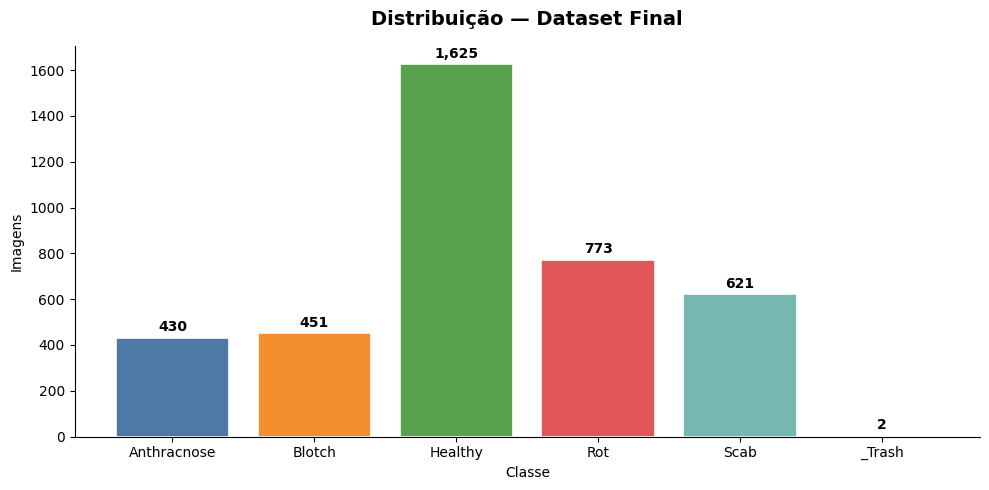


📊 Gráfico: C:\Users\Utilizador\OneDrive\Área de Trabalho\script_apple\pipeline_ALL_night\distribuicao_final.png

✅ BLOCO 6 — Pipeline completa!


In [11]:
import os
from collections import defaultdict

CLASSES_ESP = ['Anthracnose','Blotch','Healthy','Rot','Scab']
contagem = defaultdict(int); total = 0
for cls in sorted(os.listdir(DIR_FINAL)):
    p = os.path.join(DIR_FINAL, cls)
    if not os.path.isdir(p): continue
    n = len([f for f in os.listdir(p) if os.path.splitext(f)[1].lower() in IMG_EXTS])
    contagem[cls] = n; total += n

print("=" * 60)
print("  📊  DATASET FINAL")
print(f"  {'Classe':<22} {'Imagens':>8}  {'%':>6}")
print("  " + "─" * 42)
for cls in sorted(contagem):
    pct = contagem[cls]/total*100 if total else 0
    ok = "✅" if cls in CLASSES_ESP else "🟡"
    print(f"  {ok} {cls:<20} {contagem[cls]:>8}  {pct:>5.1f}%")
print(f"  {'TOTAL':<22} {total:>8}")

print("\n  INTEGRIDADE:")
for c in CLASSES_ESP:
    ok = c in contagem and contagem[c] > 0
    print(f"   {c:<22}: {'✅ OK' if ok else '❌ FALTANDO!'} ({contagem.get(c,0)} imgs)")

def contar(p):
    if not os.path.isdir(p): return 0
    n=0
    for r,_,fs in os.walk(p): n+=sum(1 for f in fs if os.path.splitext(f)[1].lower() in IMG_EXTS)
    return n

print("\n  PASTAS INTERMÉDIAS:")
for n, p in [
    ("_1_raw_consolidated",   DIR_RAW),
    ("_2a_raw_prededup",      DIR_RAW_DEDUP),
    ("_2a_prededup_removidos",os.path.join(PIPELINE_DIR,"_2a_prededup_removidos")),
    ("_2b_clean_processed",   DIR_CLEAN),
    ("_3_deduped_final",      DIR_DEDUPED),
    ("_3_posdedup_removidos", os.path.join(PIPELINE_DIR,"_3_posdedup_removidos")),
    ("_quarentena_sem_valor", os.path.join(PIPELINE_DIR,"_quarentena_sem_valor")),
    ("Incerteza",             DIR_INCERTEZA),
    ("_4_dataset_final",      DIR_FINAL),
]: print(f"   {n:<30}: {contar(p):>6} imgs")

print(f"\n🎯 Pronto: {DIR_FINAL}")
try:
    import matplotlib.pyplot as plt
    cp=[c for c in sorted(contagem) if contagem[c]>0]; vs=[contagem[c] for c in cp]
    fig,ax=plt.subplots(figsize=(10,5))
    bs=ax.bar(cp,vs,color=['#4e79a7','#f28e2b','#59a14f','#e15759','#76b7b2'][:len(cp)],edgecolor='white',linewidth=1.2)
    ax.set_title("Distribuição — Dataset Final",fontsize=14,fontweight='bold',pad=15)
    ax.set_xlabel("Classe"); ax.set_ylabel("Imagens")
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    for b in bs:
        h=b.get_height()
        ax.text(b.get_x()+b.get_width()/2.,h+max(vs)*0.01,f'{int(h):,}',ha='center',va='bottom',fontsize=10,fontweight='bold')
    plt.tight_layout()
    gp=os.path.join(PIPELINE_DIR,"distribuicao_final.png")
    plt.savefig(gp,dpi=150,bbox_inches='tight'); plt.show()
    print(f"\n📊 Gráfico: {gp}")
except ImportError: print("[matplotlib não disponível]")

print("\n✅ BLOCO 6 — Pipeline completa!")